0. Setup

In the section below, we install all required project dependencies.
In the first cell, we are installing [Ollama](https://ollama.com), the most popular way to build with open models.

In the next cell, we install all the Python dependencies needed for the study.

In [11]:
%%bash
sudo apt-get update && curl -fsSL https://ollama.com/install.sh | sh

# In the terminal, run in two different tabs:
# ollama serve
# ollama run gemma4

Hit:1 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:2 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease
Hit:3 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:4 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:5 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:6 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Reading package lists...


W: https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64/InRelease: Key is stored in legacy trusted.gpg keyring (/etc/apt/trusted.gpg), see the DEPRECATION section in apt-key(8) for details.
>>> Cleaning up old version at /usr/local/lib/ollama
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...


>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


In [12]:
%pip install "polars[gpu]" \
    spacy \
    seaborn \
    textstat \
    matplotlib \
    pyarrow \
    typing-extensions \
    pyarrow==24.0.0 \
    seaborn==0.13.2 \
    spacy==3.8.13 \
    textstat==0.7.13 \
    transformers==5.10.2 \
    click==8.0.4 \
    click-completion>=0.5.2 \
&& spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 47.2 MB/s  0:00:00eta 0:00:01
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
Note: you may need to restart the kernel to use updated packages.


In [13]:
import os
import re
import json
import polars
import spacy
import seaborn
import textstat
from itertools import permutations
from matplotlib import pyplot


In [14]:
### reusable functions

def load_parquet(parquet_name: str):
    if os.path.exists(parquet_name):
        return polars.read_parquet(parquet_name)

def paragraphs_extractor(text):
    splitted = re.split(r"(\n\n|\t|\r|\-*|\s*\n\s*)", text)
    return [
        re.sub(r"[\s{2,}|\n\|t]", " ", row).lower().strip()
        for row in splitted if "\n" not in row and row
    ]

CLAUSE_DEPS = {"ROOT", "ccomp", "xcomp", "advcl", "relcl", "conj"}

def extract_clauses_from_doc(doc):
    clauses = []
    for token in doc:
        if token.pos_ == "VERB" and token.dep_ in CLAUSE_DEPS:
            span = doc[token.left_edge.i : token.right_edge.i + 1]
            clauses.append(span.text.lower())
    return clauses

1. CUAD Data loading

In [15]:
if (cuad_legal := load_parquet("0001_cuad_dataset.parquet")) is None:
    with open("./CUADv1.json") as cuad:
        cuad_json = json.load(cuad.buffer)

    legal_pieces = {}
    for data in cuad_json.get("data"):
        full_context = ""
        for paragraph in data.get("paragraphs"):
            if context := paragraph.get("context", ""):
                full_context += context
        legal_pieces[data.get("title")] = full_context


    cuad_legal = polars.DataFrame(legal_pieces)
    cuad_legal = cuad_legal.transpose(include_header=True)
    cuad_legal.columns = ["title", "paragraphs"]

    ### Parquet checkpoint
    cuad_legal.write_parquet("0001_cuad_dataset.parquet")


2. CUAD Data parsing

In [16]:
# Sampling data
cuad_legal.select("paragraphs")[0,0][:500]

'EXHIBIT 10.6\n\n                              DISTRIBUTOR AGREEMENT\n\n         THIS  DISTRIBUTOR  AGREEMENT (the  "Agreement")  is made by and between Electric City Corp.,  a Delaware  corporation  ("Company")  and Electric City of Illinois LLC ("Distributor") this 7th day of September, 1999.\n\n                                    RECITALS\n\n         A. The  Company\'s  Business.  The Company is  presently  engaged in the business  of selling an energy  efficiency  device,  which is  referred to as an '

In [17]:
# Here we are trying to load cached file if it exists, otherwise we will need to reprocess everything
FILENAME = "cuad_sentence_extracted.parquet"

nlp = spacy.load("en_core_web_sm")

if os.path.exists(FILENAME):
    cuad_legal = polars.read_parquet(FILENAME)

else:
    cuad_legal = cuad_legal.with_columns(
        polars.col("paragraphs").map_elements(paragraphs_extractor)
    )

    all_paragraphs = cuad_legal["paragraphs"].explode().to_list()
    docs = nlp.pipe(all_paragraphs, batch_size=64, n_process=4)
    clauses = [extract_clauses_from_doc(doc) for doc in docs]
    cuad_legal = cuad_legal.with_columns(
        polars.Series("sentences", clauses)
    )

    cuad_legal.write_parquet(FILENAME)

cuad_legal.head(5)

title,paragraphs,sentences
str,str,list[str]
"""LIMEENERGYCO_09_09_1999-EX-10-…","""EXHIBIT 10.6 …","[""exhibit 10.6 distributor agreement this distributor agreement (the ""agreement"") is made by and between electric city corp., a delaware corporation (""company"") and electric city of illinois llc (""distributor"") this 7th day of september, 1999. "", ""which is referred to as an ""energy saver"" which may be improved or otherwise changed from its present composition (the ""products"""", … ""in witness whereof the parties have executed this agreement as of the date first abovementioned. ""]"
"""WHITESMOKE,INC_11_08_2011-EX-1…","""Exhibit 10.26 CONFIDENTIAL …","[""exhibit 10.26 confidential treatment has been requested as to certain portions of this document."", ""which has been omitted herein and replaced with an asterisk"", … ""if the continued use of the primary application is conditioned on the other applications being installed and active on the end user's computer google confidential - 40""]"
"""LohaCompanyltd_20191209_F-1_EX…","""Exhibit 10.16 SUPPLY CONTRACT …","[""signed by the buyer and seller on , in hong kong"", ""general provisions 1.1"", … ""after signed by both parties""]"
"""CENTRACKINTERNATIONALINC_10_29…","""1 …","[""o 561.394-9773 fax 1733 avenida del sol, boca raton, florida, 33432 web site hosting agreement this web site hosting agreement (""this agreement"") is entered into this 6th day of april, 1999 by and between centrack international, a florida corporation (""the customer""), and i-on interactive, a florida corporation (""i-on""). definitions as used in this agreement"", ""i-on interactive, a florida corporation (""i-on""). definitions as used in this agreement"", … ""in witness whereof, the parties have executed this agreement as of the date first set forth above. ""]"
"""NELNETINC_04_08_2020-EX-1-JOIN…","""Exhibit 1 JOINT FILING AGREEM…","[""the undersigned hereby agree to jointly prepare and file with the applicable regulatory authorities this schedule 13g or schedule 13d and any future amendments thereto reporting each of the undersigned's ownership of securities of the issuer named herein, and hereby affirm that such schedule 13g or schedule 13d is being filed on behalf of each of the undersigned pursuant to and in accordance with the provisions of rule 13d-1(k) under the securities exchange act of 1934."", ""to jointly prepare and file with the applicable regulatory authorities"", … ""dated: march 27, 2020. ""]"


3. Applying metrics
    - Flesch-Kincaid
    - Flesch Read Ease
    - Gunning Fog Index

In [18]:
### Grading the text complexity with Flesch-Kincaid
cuad_legal = cuad_legal.explode("sentences", empty_as_null=False)

# Adding Flesch-Kincaid Grade Level
cuad_legal = cuad_legal.with_columns(
    polars.col("sentences").map_elements(
        lambda sentence: textstat.flesch_kincaid_grade(sentence)
    ).alias("fk_grade")
)

# Adding Dale-Chall Readability Score
cuad_legal = cuad_legal.with_columns(
    polars.col("sentences").map_elements(
        lambda sentence: textstat.dale_chall_readability_score(sentence)
    ).alias("dc_readability_score")
)

# Adding Lix
cuad_legal = cuad_legal.with_columns(
    polars.col("sentences").map_elements(
        lambda sentence: textstat.lix(sentence)
    ).alias("lix")
)

# Adding Difficult Words Density
cuad_legal = cuad_legal.with_columns(
    polars.col("sentences").map_elements(
        lambda sentence: textstat.lix(sentence) / (textstat.lexicon_count(sentence) or 1),
        return_dtype=polars.Float64
    ).alias("word_density")
)



In [20]:
# Checking the first five rows of the dataframe.
cuad_legal.head(5)

title,paragraphs,sentences,fk_grade,dc_readability_score,lix,word_density
str,str,str,f64,f64,f64,f64
"""LIMEENERGYCO_09_09_1999-EX-10-…","""EXHIBIT 10.6 …","""exhibit 10.6 …",14.987059,11.445876,61.117647,1.797578
"""LIMEENERGYCO_09_09_1999-EX-10-…","""EXHIBIT 10.6 …","""which is referred to as an ""e…",11.142857,9.941433,54.333333,2.587302
"""LIMEENERGYCO_09_09_1999-EX-10-…","""EXHIBIT 10.6 …","""which may be improved or oth…",8.541538,9.139762,59.153846,4.550296
"""LIMEENERGYCO_09_09_1999-EX-10-…","""EXHIBIT 10.6 …","""otherwise changed from its p…",9.655,9.95455,70.5,8.8125
"""LIMEENERGYCO_09_09_1999-EX-10-…","""EXHIBIT 10.6 …","""the company may engage in the …",18.37697,11.972088,72.393939,2.193756


4. Data Visualisation

In [ ]:

df = cuad_legal.to_pandas()
seaborn.set_theme(style="whitegrid")

metrics = [
    ("fk_grade", "Flesch-Kincaid Grade Level", "Grade level", [8, 12]),
    ("dc_readability_score", "Dale-Chall Readability Score",  "Raw score (higher = harder)", [4.9, 9.0]),
    ("lix", "LIX", "LIX (higher = harder)", [30, 50]),
    ("word_density", "Word Density (LIX / word count)", "Ratio", []),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (col, title, xlabel, thresh) in zip(axes.flat, metrics):
    data = df[col].dropna()

    seabor.histplot(data, bins=30, kde=True, ax=ax, color="#4C72B0")

    mean, median = data.mean(), data.median()
    ax.axvline(mean,   color="crimson",  ls="--", lw=1.5, label=f"mean = {mean:.2f}")
    ax.axvline(median, color="seagreen", ls=":",  lw=1.5, label=f"median = {median:.2f}")

    for t in thresh:                       # standard band boundaries, gray
        ax.axvline(t, color="gray", ls="-.", lw=1, alpha=0.7)

    ax.set_title(title, fontsize=12, weight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Qty of sentences")
    ax.legend(loc="upper right", fontsize=8)

pyplot.suptitle(
    "Readability metric distributions — CUAD legal sentences",
    fontsize=14,
    weight="bold"
)

pyplot.tight_layout()
pyplot.show()

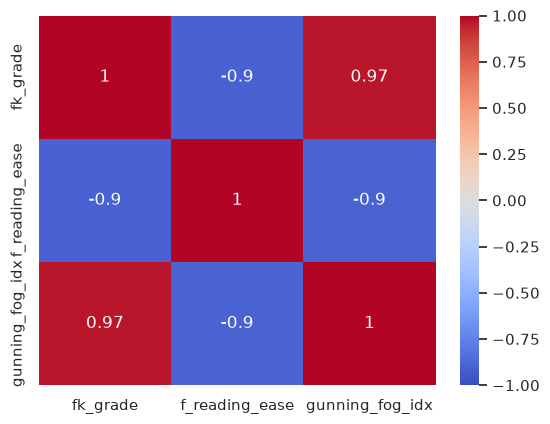

In [14]:
from itertools import permutations

# relation_analysis = cuad_legal.filter(
#     (polars.col("fk_grade") > 20) &
#     (polars.col("f_reading_ease") < 30) &
#     (polars.col("f_reading_ease") > 0) &
#     (polars.col("gunning_fog_idx") > 13)
# )

# size = int(len(relation_analysis) * 0.02)

# relation_analysis = (
#     relation_analysis
#         .sample(size)
#         .select(["fk_grade", "f_reading_ease", "readability_idx"])
#         .to_pandas()
# )

# metrics = permutations(["f_reading_ease", "readability_idx", "fk_grade"], 2)

seaborn.heatmap(
    cuad_legal.select(["fk_grade", "f_reading_ease", "gunning_fog_idx"]).to_pandas().corr(method="pearson"),
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
pyplot.show()


| Metric | Description | Scale | Interpretation |
| --- | --- | --- | --- |
| **[Flesch–Kincaid Grade](ca://s?q=Explain_Flesch_Kincaid)** | Estimates U.S. grade level needed to understand the text | ~0–20+ | Higher = more complex; legal text often 14–20 |
| **[Flesch Reading Ease](ca://s?q=Explain_readability_score)** | Measures ease of reading based on sentence length + syllables | 0–100 | Higher = easier; legal text often <30 |
| **[Automated Readability Index](ca://s?q=Explain_Automated_Readability_Index)** | Grade‑level estimate using characters per word + words per sentence | ~0–20+ | Higher = more complex; stable for jargon-heavy text |

In [15]:
corr = cuad_legal[['fk_grade','f_reading_ease','gunning_fog_idx']].corr()

In [17]:
print(repr(corr['fk_grade','f_reading_ease']))


shape: (3, 2)
┌───────────┬────────────────┐
│ fk_grade  ┆ f_reading_ease │
│ ---       ┆ ---            │
│ f64       ┆ f64            │
╞═══════════╪════════════════╡
│ 1.0       ┆ -0.903473      │
│ -0.903473 ┆ 1.0            │
│ 0.966127  ┆ -0.897556      │
└───────────┴────────────────┘
